# Tensors inside nested columns

Making extension types work within nested columns

The last two parts register kinds of column from outside the package: one wrapping awkward array, and a
spectrum type with its own methods, units and plots.

In [1]:
import numpy as np
import pandas as pd

import nested_pandas as npd
from nested_pandas import NestedFrame, TensorSeries

rng = np.random.default_rng(42)

### A tensor column

A `TensorSeries` holds one numpy array of the same shape per row. Here: three 16×16 image cutouts.

In [2]:
def make_cutouts(n, size=16):
    """n noisy images of a blob with a random position, width and brightness."""
    y, x = np.mgrid[:size, :size]
    cx, cy = rng.uniform(5, size - 5, (2, n, 1, 1))
    width = rng.uniform(1.5, 3.0, (n, 1, 1))
    amplitude = rng.uniform(50, 200, (n, 1, 1))
    blobs = amplitude * np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * width**2))
    return blobs + rng.normal(0, 3, (n, size, size))


cutouts = TensorSeries.from_stack(make_cutouts(3), name="cutout")
cutouts

,cutout
0,110-4.97
1,102-5.27
2,157-6.18


In [3]:
print(type(cutouts).__name__, "|", cutouts.dtype, "|", cutouts.tensor_shape)
cutouts[0].shape, cutouts.to_stack().shape

TensorSeries | tensor[double, (16, 16)] | (16, 16)


((16, 16), (3, 16, 16))

### Tensors inside a nested column

Now the more interesting case: four sources, each with a few observations, and every observation has
its own cutout. The observations start as a flat table, indexed by the source they belong to.

In [4]:
sources = NestedFrame(
    {"ra": [10.1, 10.4, 11.2, 11.9], "dec": [-5.0, -5.3, -4.1, -4.6], "field": ["A", "A", "B", "B"]},
    index=pd.Index([100, 101, 102, 103], name="source_id"),
)

n_obs = [3, 2, 4, 3]
source_of_obs = np.repeat(sources.index, n_obs)
observations = pd.DataFrame(
    {
        "t": np.round(rng.uniform(0, 30, sum(n_obs)), 2),
        "flux": np.round(rng.uniform(10, 100, sum(n_obs)), 1),
        "cutout": TensorSeries.from_stack(make_cutouts(sum(n_obs)), index=source_of_obs),
    },
    index=source_of_obs,
)
observations

,t,flux,cutout
source_id,,,
100,0.12,36.5,[16×16] float64
100,0.50,69.7,[16×16] float64
100,29.79,85.3,[16×16] float64
101,17.54,11.6,[16×16] float64
101,3.81,63.6,[16×16] float64
102,26.92,30.8,[16×16] float64
102,26.41,88.6,[16×16] float64
102,16.09,32.8,[16×16] float64
102,18.65,65.0,[16×16] float64


In [5]:
nf = sources.join_nested(observations, "lc")
nf.dtypes["lc"]

nested<t: [double], flux: [double], cutout: [tensor[double, (16, 16)]]>

The dtype of the nested column names the tensor sub-column by its own dtype, and that name parses
back to the same dtype.

In [6]:
pd.api.types.pandas_dtype(str(nf.dtypes["lc"])) == nf.dtypes["lc"]

True

### Display

In a notebook, each nested cell is a small table and its tensors are rendered as they are for a
top-level tensor column: thumbnails for images, plots for long vectors, the values for small tensors.
The text repr uses a short descriptor instead.

In [7]:
nf

ra  dec field                                                 lc
source_id                                                                    
100        10.1 -5.0     A  [{t: 0.12, flux: 36.5, cutout: [16×16] float64...
101        10.4 -5.3     A  [{t: 17.54, flux: 11.6, cutout: [16×16] float6...
102        11.2 -4.1     B  [{t: 26.92, flux: 30.8, cutout: [16×16] float6...
103        11.9 -4.6     B  [{t: 8.2, flux: 59.8, cutout: [16×16] float64}...

In [8]:
print(nf)

             ra  dec field                                                 lc
source_id                                                                    
100        10.1 -5.0     A  [{t: 0.12, flux: 36.5, cutout: [16×16] float64...
101        10.4 -5.3     A  [{t: 17.54, flux: 11.6, cutout: [16×16] float6...
102        11.2 -4.1     B  [{t: 26.92, flux: 30.8, cutout: [16×16] float6...
103        11.9 -4.6     B  [{t: 8.2, flux: 59.8, cutout: [16×16] float64}...


### Access always gives a `TensorSeries`

Whichever way the sub-column is reached, it is a `TensorSeries` of shaped tensors, flattened over the
nested rows.

In [9]:
paths = {
    'nf["lc.cutout"]': nf["lc.cutout"],
    'nf["lc"]["cutout"]': nf["lc"]["cutout"],
    'nf["lc"].nest["cutout"]': nf["lc"].nest["cutout"],
    'nf["lc"].nest.to_flat()["cutout"]': nf["lc"].nest.to_flat()["cutout"],
    'nf.explode("lc")["cutout"]': nf.explode("lc")["cutout"],
}
for how, series in paths.items():
    print(f"{how:36s} {type(series).__name__:13s} {series.to_stack().shape}")

nf["lc.cutout"]                      TensorSeries  (12, 16, 16)
nf["lc"]["cutout"]                   TensorSeries  (12, 16, 16)
nf["lc"].nest["cutout"]              TensorSeries  (12, 16, 16)
nf["lc"].nest.to_flat()["cutout"]    TensorSeries  (12, 16, 16)
nf.explode("lc")["cutout"]           TensorSeries  (12, 16, 16)


The nested rows of one source are a small frame, and its tensor column is typed too:

In [10]:
one_source = nf["lc"].iloc[0]
print(type(one_source).__name__, "|", type(one_source["cutout"]).__name__, "|", one_source["cutout"][0].shape)
one_source

NestedFrame | TensorSeries | (16, 16)


,t,flux,cutout
0,0.120000,36.500000,149-6.25
1,0.500000,69.700000,48.9-6.31
2,29.790000,85.300000,183-5.83


### Row operations

Filtering nested rows, filtering sources, and operations that introduce missing rows all keep the
tensors.

In [11]:
bright = nf.query("lc.flux > 50")
print("observations kept:", bright["lc.cutout"].to_stack().shape[0], "of", nf["lc.cutout"].to_stack().shape[0])
bright

observations kept: 7 of 12


ra  dec field                                                 lc
source_id                                                                    
100        10.1 -5.0     A  [{t: 0.5, flux: 69.7, cutout: [16×16] float64}...
101        10.4 -5.3     A   [{t: 3.81, flux: 63.6, cutout: [16×16] float64}]
102        11.2 -4.1     B  [{t: 26.41, flux: 88.6, cutout: [16×16] float6...
103        11.9 -4.6     B  [{t: 8.2, flux: 59.8, cutout: [16×16] float64}...

In [12]:
print(nf[nf["dec"] < -4.5]["lc.cutout"].to_stack().shape)
nf[nf["dec"] < -4.5]["lc.cutout"]

(8, 16, 16)


,cutout
100,149-6.25
100,48.9-6.31
100,183-5.83
101,99.3-6.05
101,148-4.41
103,126-3.99
103,95.7-5.85
103,121-5.81


In [13]:
nf.sort_values("lc.flux", ascending=False)["lc"]

source_id
100    [{t: 29.79, flux: 85.3, cutout: [16×16] float6...
101    [{t: 3.81, flux: 63.6, cutout: [16×16] float64...
102    [{t: 26.41, flux: 88.6, cutout: [16×16] float6...
103    [{t: 17.84, flux: 71.0, cutout: [16×16] float6...
Name: lc, dtype: nested<t: [double], flux: [double], cutout: [tensor[double, (16, 16)]]>

### Setting tensor sub-columns

A numpy array with one tensor per nested row becomes a tensor sub-column. Small tensors, like the
2-element centroid below, show their values instead of a picture.

In [14]:
stack = nf["lc.cutout"].to_stack()

# background-subtracted cutouts: one (16, 16) tensor per observation
nf["lc.clean"] = stack - np.median(stack, axis=(1, 2), keepdims=True)

# brightest pixel of every cutout: one (2,) tensor per observation
peak = stack.reshape(len(stack), -1).argmax(axis=1)
nf["lc.peak_yx"] = np.stack(np.unravel_index(peak, stack.shape[1:]), axis=1)

nf.dtypes["lc"]

nested<t: [double], flux: [double], cutout: [tensor[double, (16, 16)]], clean: [tensor[double, (16, 16)]], peak_yx: [tensor[int64, (2,)]]>

In [15]:
nf[["ra", "lc.flux", "lc.clean", "lc.peak_yx"]]

ra                                                 lc
source_id                                                         
100        10.1  [{flux: 36.5, clean: [16×16] float64, peak_yx:...
101        10.4  [{flux: 11.6, clean: [16×16] float64, peak_yx:...
102        11.2  [{flux: 30.8, clean: [16×16] float64, peak_yx:...
103        11.9  [{flux: 59.8, clean: [16×16] float64, peak_yx:...

### Row functions

`map_rows` hands a row function all the tensors of one source as a single `(n, *shape)` array.

In [16]:
def coadd_stats(cutouts, flux):
    coadd = cutouts.mean(axis=0)
    return {"n_obs": cutouts.shape[0], "coadd_peak": round(float(coadd.max()), 1), "mean_flux": flux.mean()}


nf.map_rows(coadd_stats, columns=["lc.cutout", "lc.flux"], row_container="args")

,n_obs,coadd_peak,mean_flux
source_id,,,
100,3,121.8,63.833333
101,2,84.3,37.600000
102,4,89.1,54.300000
103,3,76.6,58.833333


### Parquet round trip

In [17]:
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "sources.parquet"
    nf.to_parquet(path)
    loaded = npd.read_parquet(path)

print(loaded.dtypes["lc"])
np.array_equal(loaded["lc.cutout"].to_stack(), nf["lc.cutout"].to_stack())

nested<t: [double], flux: [double], cutout: [tensor[double, (16, 16)]], clean: [tensor[double, (16, 16)]], peak_yx: [tensor[int64, (2,)]]>


True

## Part 2 — Nested columns inside nested columns

Since we have extension columns inside nested columns, how hard is it to add nested columns inside nested columns?

### e.g. lightcurves of spectra

A spectroscopic time series has two levels below each object: a **light curve** of epochs, and for
every epoch a **spectrum** of wavelength bins. That is a nested column `lc` with a nested sub-column
`spectrum`.

It is built from the inside out: pack the spectra into the epochs, then pack the epochs into the
objects.

In [18]:
objects = NestedFrame(
    {"ra": [10.1, 10.4, 11.2, 11.9], "z": [0.02, 0.15, 0.31, 0.08], "field": ["A", "A", "B", "B"]},
    index=pd.Index([100, 101, 102, 103], name="object_id"),
)

# epochs: a few per object
n_epochs = [3, 2, 4, 3]
epochs = NestedFrame(
    {
        "object_id": np.repeat(objects.index, n_epochs),
        "mjd": np.round(60000 + np.sort(rng.uniform(0, 100, sum(n_epochs))), 1),
        "exptime": rng.choice([300.0, 600.0, 900.0], sum(n_epochs)),
    }
)

# spectra: a different number of wavelength bins for every epoch
n_bins = rng.integers(4, 9, len(epochs))
epoch_of_bin = np.repeat(epochs.index, n_bins)
wave = np.concatenate([np.linspace(4000, 9000, n) for n in n_bins]).round(0)
spectra = pd.DataFrame(
    {
        "wave": wave,
        "flux": np.round(10 + 5 * np.sin(wave / 800) + rng.normal(0, 1, len(wave)), 2),
    },
    index=epoch_of_bin,
)

epochs = epochs.join_nested(spectra, "spectrum")  # one spectrum per epoch
nf2 = objects.join_nested(epochs.set_index("object_id"), "lc")  # one light curve per object
nf2

ra     z field                                                 lc
object_id                                                                     
100        10.1  0.02     A  [{mjd: 60008.8, exptime: 600.0, spectrum: [{wa...
101        10.4  0.15     A  [{mjd: 60025.1, exptime: 600.0, spectrum: [{wa...
102        11.2  0.31     B  [{mjd: 60045.3, exptime: 600.0, spectrum: [{wa...
103        11.9  0.08     B  [{mjd: 60079.6, exptime: 600.0, spectrum: [{wa...

In [19]:
nf2.dtypes["lc"]

nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double]>]>

In [20]:
print(nf2)

             ra     z field                                                 lc
object_id                                                                     
100        10.1  0.02     A  [{mjd: 60008.8, exptime: 600.0, spectrum: [{wa...
101        10.4  0.15     A  [{mjd: 60025.1, exptime: 600.0, spectrum: [{wa...
102        11.2  0.31     B  [{mjd: 60045.3, exptime: 600.0, spectrum: [{wa...
103        11.9  0.08     B  [{mjd: 60079.6, exptime: 600.0, spectrum: [{wa...


#### A more compact display

Showing every level in full gets large quickly. `compact_view()` displays the same frame, but a nested
column inside a nested column — here each epoch's `spectrum` — shows only its sub-column names and its
number of rows. Everything else is displayed as before.

In [21]:
nf2.compact_view()

ra     z field                                                 lc
object_id                                                                     
100        10.1  0.02     A  [{mjd: 60008.8, exptime: 600.0, spectrum: [wav...
101        10.4  0.15     A  [{mjd: 60025.1, exptime: 600.0, spectrum: [wav...
102        11.2  0.31     B  [{mjd: 60045.3, exptime: 600.0, spectrum: [wav...
103        11.9  0.08     B  [{mjd: 60079.6, exptime: 600.0, spectrum: [wav...

### Paths reach any depth

The biggest change for inner nested is making the dot notation selection work. I refactored it so that all path strings resolve into ColumnPath type, and all call sites use this object to

A dotted name walks down through the nested columns. Sub-columns come back flat, indexed by the
top-level row they belong to, and a nested sub-column is a `NestedSeries`.

In [22]:
spectrum = nf2["lc.spectrum"]
print(type(spectrum).__name__, "with columns", spectrum.columns, "- one value per epoch:", len(spectrum))
spectrum

NestedSeries with columns ['wave', 'flux'] - one value per epoch: 12


object_id
100    [{wave: 4000.0, flux: 5.15}; …] (7 rows)
100    [{wave: 4000.0, flux: 5.14}; …] (7 rows)
100    [{wave: 4000.0, flux: 4.38}; …] (5 rows)
101    [{wave: 4000.0, flux: 4.97}; …] (6 rows)
101    [{wave: 4000.0, flux: 3.64}; …] (8 rows)
102    [{wave: 4000.0, flux: 5.95}; …] (4 rows)
102    [{wave: 4000.0, flux: 4.85}; …] (4 rows)
102    [{wave: 4000.0, flux: 4.08}; …] (5 rows)
102    [{wave: 4000.0, flux: 4.17}; …] (7 rows)
103    [{wave: 4000.0, flux: 4.56}; …] (5 rows)
103    [{wave: 4000.0, flux: 7.44}; …] (8 rows)
103    [{wave: 4000.0, flux: 5.46}; …] (8 rows)
Name: spectrum, dtype: nested<wave: [double], flux: [double]>

In [23]:
nf2["lc.spectrum.flux"]

object_id
100     5.15
100    10.11
       ...  
103     6.95
103     4.84
Name: flux, Length: 74, dtype: double[pyarrow]

Going step by step gives the same types: the light curve of one object, then the spectrum of one of its epochs.

In [24]:
light_curve = nf2["lc"].iloc[0]
print(type(light_curve).__name__, "|", type(light_curve["spectrum"]).__name__)
light_curve

NestedFrame | NestedSeries


mjd  exptime                                  spectrum
0  60008.8    600.0  [{wave: 4000.0, flux: 5.15}; …] (7 rows)
1  60019.3    600.0  [{wave: 4000.0, flux: 5.14}; …] (7 rows)
2  60022.2    900.0  [{wave: 4000.0, flux: 4.38}; …] (5 rows)

In [25]:
light_curve["spectrum"][0]

,wave,flux
0,4000.0,5.15
1,4833.0,10.11
2,5667.0,11.62
3,6500.0,14.76
4,7333.0,11.24
5,8167.0,5.74
6,9000.0,7.54


A list of names selects sub-columns at several depths at once:

In [26]:
nf2[["z", "lc.mjd", "lc.spectrum.flux"]].dtypes

z                                               float64
lc    nested<mjd: [double], spectrum: [nested<flux: ...
dtype: object

### Assigning

New or existing sub-columns can be set at any depth, with `[]` or with `eval`.

In [27]:
nf2["lc.spectrum.snr"] = nf2["lc.spectrum.flux"] ** 0.5  # photon-noise limited
nf2 = nf2.eval("lc.spectrum.flux_jy = lc.spectrum.flux * 1e-3")
nf2.dtypes["lc"]

nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double], snr: [double], flux_jy: [double]>]>

A column of the level above is repeated into each row below it. Doing that twice carries the
redshift of each object down to its spectra, which is what rest-frame wavelengths need.

In [28]:
nf2["lc.z"] = nf2["z"]  # object -> each of its epochs
nf2["lc.spectrum.z"] = nf2["lc.z"]  # epoch -> each of its wavelength bins
nf2 = nf2.eval("lc.spectrum.rest_wave = lc.spectrum.wave / (1 + lc.spectrum.z)")
nf2["lc"][101]["spectrum"][0][["wave", "z", "rest_wave"]]

,wave,z,rest_wave
0,4000.0,0.15,3478.260870
1,5000.0,0.15,4347.826087
2,6000.0,0.15,5217.391304
3,7000.0,0.15,6086.956522
4,8000.0,0.15,6956.521739
5,9000.0,0.15,7826.086957


### Filtering, sorting and dropping

`query`, `dropna` and `sort_values` work on the innermost nested column a path points into — here the
spectra — leaving the epochs and objects above untouched.

In [29]:
red = nf2.query("lc.spectrum.wave > 6500")
print("wavelength bins:", len(nf2["lc.spectrum.wave"]), "->", len(red["lc.spectrum.wave"]))
print("epochs:         ", len(nf2["lc.mjd"]), "->", len(red["lc.mjd"]))
red["lc"][100]["spectrum"][0][["wave", "flux"]]

wavelength bins: 74 -> 34
epochs:          12 -> 12


,wave,flux
0,7333.0,11.24
1,8167.0,5.74
2,9000.0,7.54


A query on the level above filters epochs instead, each keeping its whole spectrum:

In [30]:
long_exposures = nf2.query("lc.exptime > 300")
print("epochs:         ", len(nf2["lc.mjd"]), "->", len(long_exposures["lc.mjd"]))
print("wavelength bins:", len(nf2["lc.spectrum.wave"]), "->", len(long_exposures["lc.spectrum.wave"]))

epochs:          12 -> 11
wavelength bins: 74 -> 66


In [31]:
brightest_first = nf2.sort_values("lc.spectrum.flux", ascending=False)
brightest_first["lc"][100]["spectrum"][0][["wave", "flux"]]

,wave,flux
0,6500.0,14.76
1,5667.0,11.62
2,7333.0,11.24
3,4833.0,10.11
4,9000.0,7.54
5,8167.0,5.74
6,4000.0,5.15


In [32]:
with_gaps = nf2.copy()
flux = with_gaps["lc.spectrum.flux"].to_numpy(dtype=float, na_value=np.nan).copy()
flux[[0, 4]] = np.nan
with_gaps["lc.spectrum.flux"] = flux
len(with_gaps["lc.spectrum.flux"]), len(with_gaps.dropna(subset="lc.spectrum.flux")["lc.spectrum.flux"])

(74, 72)

In [33]:
nf2 = nf2.drop(columns=["lc.spectrum.snr", "lc.spectrum.flux_jy", "lc.spectrum.z", "lc.z"])
nf2.dtypes["lc"]

nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double], rest_wave: [double]>]>

### Both together: tensors two levels down

Nothing special is needed to combine the two parts. Grouping the frame from Part 1, cutouts included,
by field puts the tensors two levels down — still a `TensorSeries`, still drawn as thumbnails.

In [34]:
deep = NestedFrame.from_flat(
    nf[["ra", "field", "lc.flux", "lc.cutout"]].reset_index(), base_columns=[], on="field", name="sources"
)
cutouts = deep["sources.lc.cutout"]
print(deep.dtypes["sources"])
print(type(cutouts).__name__, cutouts.to_stack().shape)
deep

nested<source_id: [int64], ra: [double], lc: [nested<flux: [double], cutout: [tensor[double, (16, 16)]]>]>
TensorSeries (12, 16, 16)


sources
field                                                   
A      [{source_id: 100, ra: 10.1, lc: [{flux: 36.5, ...
B      [{source_id: 102, ra: 11.2, lc: [{flux: 30.8, ...

In [35]:
bright_deep = deep.query("sources.lc.flux > 50")
bright_deep["sources.lc.cutout"].to_stack().shape

(7, 16, 16)

### Current limits

A few things stop at one level of nesting for now and say so:

In [36]:
for attempt in (
    lambda: nf2.map_rows(lambda flux: flux.mean(), columns=["lc.spectrum.flux"]),
    lambda: nf2.fillna({"lc.spectrum.flux": 0.0}),
):
    try:
        attempt()
    except NotImplementedError as error:
        print("NotImplementedError:", error)

# these list one level only
nf2.get_subcolumns()

NotImplementedError: map_rows does not support sub-columns nested deeper than one level, given 'lc.spectrum.flux'
NotImplementedError: fillna does not support sub-columns nested deeper than one level, given 'lc.spectrum.flux'


['lc.mjd', 'lc.exptime', 'lc.spectrum']

## Part 3 — One level more: triple nesting

Nothing above is specific to two levels. Grouping the objects by the field they were observed in adds
a third: **fields** of **objects**, with **light curves**, of **spectra**.

In [37]:
fields = NestedFrame.from_flat(nf2.reset_index(), base_columns=[], on="field", name="objects")
print(fields.dtypes["objects"])
fields

nested<object_id: [int64], ra: [double], z: [double], lc: [nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double], rest_wave: [double]>]>]>


objects
field                                                   
A      [{object_id: 100, ra: 10.1, z: 0.02, lc: [{mjd...
B      [{object_id: 102, ra: 11.2, z: 0.31, lc: [{mjd...

In [38]:
print(fields)

                                                 objects
field                                                   
A      [{object_id: 100, ra: 10.1, z: 0.02, lc: [{mjd...
B      [{object_id: 102, ra: 11.2, z: 0.31, lc: [{mjd...


With three levels the compact view helps even more — only the outermost nested column is expanded:

In [39]:
fields.compact_view()

objects
field                                                   
A      [{object_id: 100, ra: 10.1, z: 0.02, lc: [mjd,...
B      [{object_id: 102, ra: 11.2, z: 0.31, lc: [mjd,...

Paths simply get one component longer, and every level keeps its type:

In [40]:
for name in ("objects", "objects.lc", "objects.lc.spectrum", "objects.lc.spectrum.flux"):
    column = fields[name]
    print(f"{name:26s} {type(column).__name__:13s} {len(column):3d} values")

objects                    NestedSeries    2 values
objects.lc                 NestedSeries    4 values
objects.lc.spectrum        NestedSeries   12 values
objects.lc.spectrum.flux   Series         74 values


In [41]:
# field -> object -> epoch -> spectrum, step by step
field_a = fields["objects"]["A"]
field_a["lc"][0]["spectrum"][0]

,wave,flux,rest_wave
0,4000.0,5.15,3921.568627
1,4833.0,10.11,4738.235294
2,5667.0,11.62,5555.882353
3,6500.0,14.76,6372.549020
4,7333.0,11.24,7189.215686
5,8167.0,5.74,8006.862745
6,9000.0,7.54,8823.529412


Assigning, `eval`, filtering and sorting work three levels down as they do two levels down:

In [42]:
fields["objects.lc.spectrum.log_flux"] = np.log10(fields["objects.lc.spectrum.flux"].to_numpy(dtype=float))
fields = fields.eval("objects.lc.spectrum.wave_nm = objects.lc.spectrum.wave / 10")

red = fields.query("objects.lc.spectrum.wave > 6500")
for name in ("objects.ra", "objects.lc.mjd", "objects.lc.spectrum.wave"):
    print(f"{name:26s} {len(fields[name]):3d} -> {len(red[name]):3d}")
red["objects"]["A"]["lc"][0]["spectrum"][0]

objects.ra                   4 ->   4
objects.lc.mjd              12 ->  12
objects.lc.spectrum.wave    74 ->  34


,wave,flux,rest_wave,log_flux,wave_nm
0,7333.0,11.24,7189.215686,1.050766,733.3
1,8167.0,5.74,8006.862745,0.758912,816.7
2,9000.0,7.54,8823.529412,0.877371,900.0


In [43]:
by_wave = fields.sort_values("objects.lc.spectrum.wave", ascending=False)
by_wave["objects.lc.spectrum.wave"].head(4).tolist()

[9000.0, 8167.0, 7333.0, 6500.0]

In [44]:
trimmed = fields.drop(columns=["objects.lc.spectrum.log_flux", "objects.z"])
trimmed[["objects.ra", "objects.lc.spectrum.wave_nm"]].dtypes["objects"]

nested<ra: [double], lc: [nested<spectrum: [nested<wave_nm: [double]>]>]>

The results match the same operations done on the doubly nested frame, since grouping by field keeps the order of the objects:

In [45]:
np.array_equal(
    red["objects.lc.spectrum.flux"].to_numpy(), nf2.query("lc.spectrum.wave > 6500")["lc.spectrum.flux"].to_numpy()
)

True

## Part 4 — Registering your own kind of column: awkward arrays

Tensors and nested columns are not special-cased anywhere: each one *registers* itself with
`nested_pandas.series.registry`, and everything shown above follows from four registrations. The same
four calls work for a column type of your own.

As an example, this wraps [awkward array](https://awkward-array.org) (`pip install awkward`), so that a
column can hold a ragged list per row — here the fluxes of the emission lines detected in each epoch,
a different number every time.

> The registry is currently an internal module, not part of the documented API.

### 1. A pandas extension type

This part is ordinary pandas, nothing to do with nested-pandas: a dtype, and an array that wraps an
`ak.Array` and converts to and from pyarrow. awkward has its own pyarrow extension type, which is what
lets a column of it be recognised later.

The dtype is registered with pandas (`@register_extension_dtype`) and can parse its own name, so
pandas understands strings like `"awkward[var * float64]"` wherever it accepts a dtype.

In [46]:
import awkward as ak
import pyarrow as pa
from pandas.api.extensions import ExtensionArray, ExtensionDtype, register_extension_dtype
from pandas.core.indexers import check_array_indexer

AWKWARD_ARROW_TYPE = type(ak.to_arrow(ak.Array([[1.0]]), extensionarray=True).type)


@register_extension_dtype
class AwkwardDtype(ExtensionDtype):
    """Dtype of a column whose values are awkward arrays, described by its pyarrow type.

    Its name is "awkward[<type of one value>]", in awkward's own notation for types, e.g.
    "awkward[var * float64]" for lists of floats of any length.
    """

    type = ak.Array
    na_value = pd.NA
    _metadata = ("datashape",)  # what equality and hashing use

    def __init__(self, pyarrow_dtype):
        self.pyarrow_dtype = pyarrow_dtype
        self.datashape = str(ak.from_arrow(pa.nulls(0, pyarrow_dtype)).type.content)

    @property
    def name(self):
        return f"awkward[{self.datashape}]"

    @classmethod
    def construct_from_string(cls, string):
        """Parse a name back to the dtype. pandas tries this for every dtype string it is given, and
        expects a TypeError for the strings which are not ours."""
        if not isinstance(string, str) or not (string.startswith("awkward[") and string.endswith("]")):
            raise TypeError(f"Cannot construct a '{cls.__name__}' from '{string}'")
        datashape = string.removeprefix("awkward[").removesuffix("]")
        try:
            form = ak.forms.from_type(ak.types.from_datashape(datashape, highlevel=False))
        except Exception as error:
            raise TypeError(f"Cannot parse the awkward type '{datashape}'") from error
        return cls(ak.to_arrow(ak.Array(form.length_zero_array()), extensionarray=True).type)

    @classmethod
    def construct_array_type(cls):
        return AwkwardExtensionArray


class AwkwardExtensionArray(ExtensionArray):
    """A pandas array wrapping an ak.Array, one element per row."""

    def __init__(self, data):
        if isinstance(data, pa.ChunkedArray):
            data = data.combine_chunks()
        self._ak = ak.from_arrow(data) if isinstance(data, pa.Array) else ak.Array(data)

    @classmethod
    def _from_sequence(cls, scalars, *, dtype=None, copy=False):
        if isinstance(scalars, cls):
            return scalars
        if isinstance(scalars, (pa.Array, pa.ChunkedArray, ak.Array)):
            return cls(scalars)
        return cls(ak.Array([None if x is None or x is pd.NA else x for x in scalars]))

    def __arrow_array__(self, type=None):
        return ak.to_arrow(self._ak, extensionarray=True)

    @property
    def dtype(self):
        return AwkwardDtype(self.__arrow_array__().type)

    def __len__(self):
        return len(self._ak)

    def __getitem__(self, item):
        if isinstance(item, (int, np.integer)):
            value = self._ak[item]
            return pd.NA if value is None else value
        return type(self)(self._ak[check_array_indexer(self, item)])

    def isna(self):
        return np.asarray(ak.is_none(self._ak))

    def take(self, indices, *, allow_fill=False, fill_value=None):
        indices = np.asarray(indices)
        if allow_fill:  # -1 means a missing value
            return type(self)(self._ak[ak.mask(indices, indices >= 0)])
        return type(self)(self._ak[indices])

    def copy(self):
        return type(self)(self._ak)

    @classmethod
    def _concat_same_type(cls, to_concat):
        return cls(ak.concatenate([array._ak for array in to_concat]))

    @property
    def nbytes(self):
        return self._ak.nbytes

    def to_numpy(self, dtype=None, copy=False, na_value=pd.NA):
        result = np.empty(len(self), dtype=object)
        for i in range(len(self)):
            result[i] = self[i]
        return result

    def __array__(self, dtype=None, copy=None):
        return self.to_numpy()

    def _formatter(self, boxed=False):
        return awkward_text

### 2. A Series type and two formatters

The Series subclass is where conveniences go. This one only adds `.ak`, the whole column as a single
`ak.Array`, which is enough to use any awkward function on it.

The text formatter is used inside the text repr of a nested column; the HTML formatter draws a cell in
a notebook, here as a small bar chart of the values.

In [47]:
class AwkwardSeries(pd.Series):
    """A Series of awkward arrays."""

    @property
    def ak(self):
        """The whole column as one ak.Array."""
        return self.array._ak


def awkward_text(value):
    return "<NA>" if value is None or value is pd.NA else f"ak{value.tolist()}"


def awkward_html_formatter():
    """A new HTML formatter for one column: each cell as a bar per value, and the number of values."""
    bars = "▁▂▃▄▅▆▇█"

    def cell_html(value):
        if value is None or value is pd.NA:
            return "&lt;NA&gt;"
        values = np.asarray(value, dtype=float)
        if len(values) == 0:
            return "<i>empty</i>"
        heights = (values / values.max() * 7).astype(int)
        chart = "".join(bars[height] for height in heights)
        return f'<span title="{value.tolist()}" style="font-size:150%">{chart}</span> <small>n={len(values)}</small>'

    return cell_html

### 3. The four registrations

- which pyarrow types are this kind of column, and how to get from the dtype back to the pyarrow type,
- which Series type its columns are returned as,
- how a cell is drawn in HTML,
- how a value is written inside a text repr.

In [48]:
from nested_pandas.series import registry

registry.register_arrow_dtype(
    AwkwardDtype,
    lambda pa_type: isinstance(pa_type, AWKWARD_ARROW_TYPE),
    lambda dtype: dtype.pyarrow_dtype,
)
registry.register_series_class(AwkwardDtype, AwkwardSeries)
registry.register_html_formatter(AwkwardDtype, awkward_html_formatter)
registry.register_text_formatter(AwkwardDtype, awkward_text)

### As a column of the frame

From here on there is no awkward-specific code in nested-pandas — it only follows the registry.

In [49]:
def random_line_fluxes(n):
    """Fluxes of the emission lines detected in each of n epochs: between zero and six lines."""
    return AwkwardExtensionArray(
        ak.Array([np.round(rng.uniform(1, 10, k), 1).tolist() for k in rng.integers(0, 7, n)])
    )


catalog = NestedFrame({"ra": [10.1, 10.4, 11.2], "lines": random_line_fluxes(3)})
print(type(catalog["lines"]).__name__, "|", catalog["lines"].dtype)
catalog

AwkwardSeries | awkward[var * float64]


,ra,lines
0,10.100000,▃▆█▄ n=4
1,10.400000,▄█▆ n=3
2,11.200000,█▄ n=2


In [50]:
print(catalog)

     ra                   lines
0  10.1  ak[3.4, 6.3, 8.8, 3.9]
1  10.4       ak[5.4, 9.6, 8.2]
2  11.2            ak[9.0, 4.5]


Because the dtype is registered with pandas, its name is a dtype anywhere pandas takes one:

In [51]:
dtype = pd.api.types.pandas_dtype("awkward[var * float64]")
print(type(dtype).__name__, "|", dtype)
pd.Series([[1.0, 2.0], [], [3.0]], dtype="awkward[var * float64]")

AwkwardDtype | awkward[var * float64]


0    ak[1.0, 2.0]
1            ak[]
2         ak[3.0]
dtype: awkward[var * float64]

### Inside a nested column

Now the same thing one level down: one ragged list of line fluxes for every epoch of the light curves
from Part 2. The dtype of `lc` names the new sub-column by its own dtype, and the cells are drawn by
the registered formatter. (`compact_view()` keeps each epoch's spectrum small.)

In [52]:
nf2["lc.lines"] = random_line_fluxes(len(nf2["lc.mjd"]))
print(nf2.dtypes["lc"])
nf2.compact_view()

nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double], rest_wave: [double]>], lines: [awkward[var * float64]]>


ra     z field                                                 lc
object_id                                                                     
100        10.1  0.02     A  [{mjd: 60008.8, exptime: 600.0, spectrum: [wav...
101        10.4  0.15     A  [{mjd: 60025.1, exptime: 600.0, spectrum: [wav...
102        11.2  0.31     B  [{mjd: 60045.3, exptime: 600.0, spectrum: [wav...
103        11.9  0.08     B  [{mjd: 60079.6, exptime: 600.0, spectrum: [wav...

In [53]:
with pd.option_context("display.max_colwidth", 100, "display.width", 200):
    print(nf2[["lc.mjd", "lc.lines"]])

                                                                         lc
object_id                                                                  
100        [{mjd: 60008.8, lines: ak[7.6, 6.6, 4.8, 5.6, 5.6]}; …] (3 rows)
101             [{mjd: 60025.1, lines: ak[4.4, 5.3, 3.3, 1.3]}; …] (2 rows)
102                               [{mjd: 60045.3, lines: ak[]}; …] (4 rows)
103                  [{mjd: 60079.6, lines: ak[2.9, 5.7, 3.5]}; …] (3 rows)


That also completes the round trip of the nested dtype's name: nested-pandas hands the part it does
not know, `awkward[var * float64]`, to pandas, which finds the dtype registered above.

In [54]:
name = str(nf2.dtypes["lc"])
print(name)
pd.api.types.pandas_dtype(name) == nf2.dtypes["lc"]

nested<mjd: [double], exptime: [double], spectrum: [nested<wave: [double], flux: [double], rest_wave: [double]>], lines: [awkward[var * float64]]>


True

Every access path returns the registered Series type, and `.ak` hands the column to awkward:

In [55]:
for how, series in {
    'nf2["lc.lines"]': nf2["lc.lines"],
    'nf2["lc"].nest["lines"]': nf2["lc"].nest["lines"],
    'nf2["lc"][100]["lines"]': nf2["lc"][100]["lines"],
    'nf2.explode("lc")["lines"]': nf2.explode("lc")["lines"],
}.items():
    print(f"{how:28s} {type(series).__name__:14s} {len(series):2d} values")

lines = nf2["lc.lines"].ak
lines

nf2["lc.lines"]              AwkwardSeries  12 values
nf2["lc"].nest["lines"]      AwkwardSeries  12 values
nf2["lc"][100]["lines"]      AwkwardSeries   3 values
nf2.explode("lc")["lines"]   AwkwardSeries  12 values


<Array [[7.6, 6.6, 4.8, 5.6, 5.6], ..., [4.6, ...]] type='12 * var * float64'>

Results computed with awkward go straight back in as ordinary sub-columns:

In [56]:
nf2["lc.n_lines"] = ak.to_numpy(ak.num(lines))
nf2["lc.total_line_flux"] = ak.to_numpy(ak.sum(lines, axis=1))
nf2["lc"][100][["mjd", "lines", "n_lines", "total_line_flux"]]

,mjd,lines,n_lines,total_line_flux
0,60008.800000,█▇▅▆▆ n=5,5,30.200000
1,60019.300000,▂█ n=2,2,6.700000
2,60022.200000,█▆▇▄▅▂ n=6,6,35.900000


Filtering, missing rows and parquet all carry the awkward sub-column along:

In [57]:
with_lines = nf2.query("lc.n_lines > 2")
print("epochs:", len(nf2["lc.mjd"]), "->", len(with_lines["lc.mjd"]))
print("lines per epoch left:", ak.num(with_lines["lc.lines"].ak).tolist())

print("after reindex:", nf2.reindex([100, 999])["lc"].isna().tolist())

with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "with_lines.parquet"
    nf2.to_parquet(path)
    loaded = npd.read_parquet(path)
print(type(loaded["lc.lines"]).__name__, "|", ak.all(loaded["lc.lines"].ak == nf2["lc.lines"].ak))

epochs: 12 -> 9
lines per epoch left: [5, 6, 4, 3, 5, 3, 3, 5, 3]
after reindex: [False, True]
AwkwardSeries | True


And it nests as deep as anything else — grouped by field, the lines are two levels down:

In [58]:
fields_with_lines = NestedFrame.from_flat(nf2.reset_index(), base_columns=[], on="field", name="objects")
deep_lines = fields_with_lines["objects.lc.lines"]
print(type(deep_lines).__name__, "|", len(deep_lines), "values |", deep_lines.dtype)
fields_with_lines.compact_view()

AwkwardSeries | 12 values | awkward[var * float64]


objects
field                                                   
A      [{object_id: 100, ra: 10.1, z: 0.02, lc: [mjd,...
B      [{object_id: 102, ra: 11.2, z: 0.31, lc: [mjd,...

## Part 5 — A second kind of your own: spectra

The awkward example wrapped an existing library. This one defines a domain type from scratch: a column
where **each value is a whole spectrum** — wavelengths and fluxes — with its own methods, its own units,
and drawn as a plot.

Part 2 held spectra as a nested column. A spectrum is stored exactly the same way here (a list of
`{wave, flux}` records); what makes it a kind of its own is a pyarrow *extension type*: a named label
on that storage, which the registry can recognise.

### 1. The types

A pyarrow extension type, a pandas dtype, and an array holding the pyarrow data. One value comes out
as a small `Spectrum` object.

The type has two parameters, the **units** of the wavelengths and of the fluxes. They are part of the
pyarrow type, so they travel with the data (into parquet too), and part of the name of the dtype, which
pandas can parse: `"spectrum[Å, mJy]"`.

In [59]:
import json
import re

import pyarrow.compute as pc
from pandas.api.extensions import register_extension_dtype


class SpectrumArrowType(pa.ExtensionType):
    """pyarrow type of a spectrum: a list of {wave, flux} records, labelled with the units of both."""

    def __init__(self, wave_unit="Å", flux_unit="mJy"):
        self.wave_unit, self.flux_unit = wave_unit, flux_unit
        super().__init__(pa.large_list(pa.struct({"wave": pa.float64(), "flux": pa.float64()})), "demo.spectrum")

    # how the units are stored with the data, e.g. in a parquet file
    def __arrow_ext_serialize__(self):
        return json.dumps({"wave_unit": self.wave_unit, "flux_unit": self.flux_unit}).encode()

    @classmethod
    def __arrow_ext_deserialize__(cls, storage_type, serialized):
        return cls(**json.loads(serialized))

    # without these pyarrow would call spectra in different units the same type
    def __eq__(self, other):
        return isinstance(other, SpectrumArrowType) and self._units == other._units

    def __hash__(self):
        return hash((SpectrumArrowType, self._units))

    @property
    def _units(self):
        return self.wave_unit, self.flux_unit


try:
    pa.register_extension_type(SpectrumArrowType())  # so that it survives parquet
except pa.ArrowKeyError:
    pass  # already registered, when this cell is run again


class Spectrum:
    """One spectrum: what a single value of the column is."""

    def __init__(self, wave, flux, wave_unit="Å", flux_unit="mJy"):
        self.wave, self.flux = np.asarray(wave, dtype=float), np.asarray(flux, dtype=float)
        self.wave_unit, self.flux_unit = wave_unit, flux_unit

    def __repr__(self):
        return f"Spectrum({len(self.wave)} bins, {self.wave_unit}, {self.flux_unit})"

    def to_frame(self):
        return pd.DataFrame({"wave": self.wave, "flux": self.flux})


@register_extension_dtype
class SpectrumDtype(ExtensionDtype):
    """Dtype of a column of spectra with wavelengths in ``wave_unit`` and fluxes in ``flux_unit``.

    Its name is "spectrum[<wave_unit>, <flux_unit>]", for example "spectrum[Å, mJy]".
    """

    type = Spectrum
    na_value = pd.NA
    _metadata = ("wave_unit", "flux_unit")  # what equality and hashing use
    _name_pattern = re.compile(r"^spectrum\[(?P<wave_unit>[^,\]]+), (?P<flux_unit>[^,\]]+)\]$")

    def __init__(self, wave_unit="Å", flux_unit="mJy"):
        if isinstance(wave_unit, SpectrumArrowType):  # built from the pyarrow type
            wave_unit, flux_unit = wave_unit.wave_unit, wave_unit.flux_unit
        self.wave_unit, self.flux_unit = wave_unit, flux_unit

    @property
    def name(self):
        return f"spectrum[{self.wave_unit}, {self.flux_unit}]"

    @property
    def pyarrow_dtype(self):
        return SpectrumArrowType(self.wave_unit, self.flux_unit)

    @classmethod
    def construct_from_string(cls, string):
        match = cls._name_pattern.match(string) if isinstance(string, str) else None
        if match is None:
            raise TypeError(f"Cannot construct a '{cls.__name__}' from '{string}'")
        return cls(match["wave_unit"], match["flux_unit"])

    @classmethod
    def construct_array_type(cls):
        return SpectrumArray


class SpectrumArray(ExtensionArray):
    """A pandas array of spectra, held as a pyarrow array of a SpectrumArrowType."""

    def __init__(self, data, dtype=None):
        if isinstance(data, pa.Array):
            data = pa.chunked_array([data])
        if not isinstance(data.type, SpectrumArrowType):  # the storage: wrap it in the extension type
            pa_type = (dtype or SpectrumDtype()).pyarrow_dtype
            storage = data.cast(pa_type.storage_type)
            data = pa.chunked_array([pa_type.wrap_array(chunk) for chunk in storage.chunks], pa_type)
        self._pa = data

    @classmethod
    def _from_sequence(cls, scalars, *, dtype=None, copy=False):
        """From Spectrum objects, missing values, or pyarrow data."""
        if isinstance(scalars, cls):
            return scalars
        if isinstance(scalars, (pa.Array, pa.ChunkedArray)):
            return cls(scalars, dtype)
        spectra = [None if spectrum is None or spectrum is pd.NA else spectrum for spectrum in scalars]
        if dtype is None:  # take the units of the first spectrum
            first = next((spectrum for spectrum in spectra if spectrum is not None), Spectrum([], []))
            dtype = SpectrumDtype(first.wave_unit, first.flux_unit)
        records = [None if spectrum is None else spectrum.to_frame().to_dict("records") for spectrum in spectra]
        return cls(pa.array(records, type=dtype.pyarrow_dtype.storage_type), dtype)

    @property
    def storage(self):
        """The spectra as a plain pyarrow list-of-records array."""
        return pa.chunked_array([chunk.storage for chunk in self._pa.chunks], self._pa.type.storage_type)

    def __arrow_array__(self, type=None):
        return self._pa

    @property
    def dtype(self):
        return SpectrumDtype(self._pa.type)

    def __len__(self):
        return len(self._pa)

    def __getitem__(self, item):
        if isinstance(item, (int, np.integer)):
            scalar = self._pa[int(item)]
            if not scalar.is_valid:
                return pd.NA
            bins = scalar.value.values
            return Spectrum(bins.field("wave").to_numpy(), bins.field("flux").to_numpy(), *self._pa.type._units)
        indices = np.arange(len(self))[check_array_indexer(self, item)]
        return type(self)(self._pa.take(indices))

    def isna(self):
        return self._pa.is_null().to_numpy()

    def take(self, indices, *, allow_fill=False, fill_value=None):
        indices = np.asarray(indices)
        if allow_fill:  # -1 means a missing value
            return type(self)(self._pa.take(pa.array(indices, mask=indices < 0)))
        return type(self)(self._pa.take(indices))

    def copy(self):
        return type(self)(self._pa)

    @classmethod
    def _concat_same_type(cls, to_concat):
        chunks = [chunk for array in to_concat for chunk in array._pa.chunks]
        return cls(pa.chunked_array(chunks, to_concat[0]._pa.type))

    @property
    def nbytes(self):
        return self._pa.nbytes

    def to_numpy(self, dtype=None, copy=False, na_value=pd.NA):
        result = np.empty(len(self), dtype=object)
        for i in range(len(self)):
            result[i] = self[i]
        return result

    def __array__(self, dtype=None, copy=None):
        return self.to_numpy()

    def _formatter(self, boxed=False):
        return spectrum_text


def spectrum_text(spectrum):
    return "<NA>" if spectrum is None or spectrum is pd.NA else repr(spectrum)

### 2. A Series type with spectrum methods, and the formatters

The Series subclass is where the domain lives: per-spectrum measurements, and `to_nested()`, which
re-reads the same data as an ordinary nested column — free, since the storage is identical.

The HTML formatter plots each spectrum with matplotlib, labelling the axes with the units of the
column. Plots are heavier than text, so it reuses the helper nested-pandas uses for tensor thumbnails:
only the first ten cells of a column are drawn, the rest show a placeholder.

In [60]:
from nested_pandas import NestedSeries
from nested_pandas.display import CappedColumnFormatter
from nested_pandas.series.ext_array import NestedExtensionArray


class SpectrumSeries(pd.Series):
    """A Series of spectra."""

    def n_bins(self):
        """Number of wavelength bins of each spectrum."""
        lengths = pc.list_value_length(self.array.storage).to_numpy(zero_copy_only=False)
        return pd.Series(lengths, index=self.index, name="n_bins")

    def mean_flux(self):
        """Mean flux of each spectrum, computed by pyarrow over all spectra at once."""
        flux = self.array.storage.combine_chunks().flatten().field("flux")
        # group the flat fluxes by the spectrum they belong to
        spectrum = np.repeat(np.arange(len(self)), self.n_bins().to_numpy())
        means = pa.table({"spectrum": spectrum, "flux": flux}).group_by("spectrum").aggregate([("flux", "mean")])
        means = means.sort_by("spectrum")
        index = self.index[means["spectrum"].to_numpy()]
        return pd.Series(means["flux_mean"].to_numpy(), index=index, name="mean_flux")

    def peak_wave(self):
        """Wavelength of the brightest bin of each spectrum."""
        peaks = [np.nan if s is pd.NA or len(s.wave) == 0 else s.wave[np.argmax(s.flux)] for s in self]
        return pd.Series(peaks, index=self.index, name="peak_wave")

    def to_nested(self):
        """The same data as a nested column with sub-columns wave and flux."""
        return NestedSeries(NestedExtensionArray(self.array.storage), index=self.index, name=self.name)


def spectrum_plot_html(spectrum):
    """HTML for one spectrum: a small plot of flux against wavelength, with the units on the axes."""
    import base64
    import io

    from matplotlib.figure import Figure
    from matplotlib.ticker import MaxNLocator

    if spectrum is None or spectrum is pd.NA:
        return "&lt;NA&gt;"
    if len(spectrum.wave) == 0:
        return "<i>empty</i>"
    grey = "#888888"  # readable on light and dark notebook themes
    figure = Figure(figsize=(2.6, 1.3), dpi=110)
    axes = figure.add_subplot()
    order = np.argsort(spectrum.wave)
    axes.plot(spectrum.wave[order], spectrum.flux[order], color="#21918c", linewidth=0.7, drawstyle="steps-mid")
    axes.set_xlabel(f"wavelength [{spectrum.wave_unit}]", fontsize=6, color=grey, labelpad=1)
    axes.set_ylabel(f"flux [{spectrum.flux_unit}]", fontsize=6, color=grey, labelpad=1)
    axes.xaxis.set_major_locator(MaxNLocator(nbins=4))
    axes.yaxis.set_major_locator(MaxNLocator(nbins=3))
    axes.tick_params(labelsize=6, length=2, pad=1, width=0.5, colors=grey)
    for side in ("top", "right"):
        axes.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        axes.spines[side].set_linewidth(0.5)
        axes.spines[side].set_color(grey)
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", transparent=True, bbox_inches="tight", pad_inches=0.03)
    png = base64.b64encode(buffer.getvalue()).decode()
    return f'<img src="data:image/png;base64,{png}" style="height:110px" title="{spectrum!r}"/>'


def spectrum_html_formatter():
    """A new HTML formatter for one column: the first ten spectra as plots, then a placeholder."""
    return CappedColumnFormatter(spectrum_plot_html, lambda spectrum: isinstance(spectrum, Spectrum))

### 3. The four registrations

In [61]:
registry.register_arrow_dtype(
    SpectrumDtype,
    lambda pa_type: isinstance(pa_type, SpectrumArrowType),
    lambda dtype: dtype.pyarrow_dtype,
)
registry.register_series_class(SpectrumDtype, SpectrumSeries)
registry.register_html_formatter(SpectrumDtype, spectrum_html_formatter)
registry.register_text_formatter(SpectrumDtype, spectrum_text)

### As a column of the frame

Four galaxies at different redshifts, each with one co-added spectrum: a continuum with the Hβ, [O III]
and Hα emission lines, shifted by the redshift.

,ra,z,coadd
200,10.100000,0.020000,
201,10.400000,0.080000,
202,11.200000,0.150000,
203,11.900000,0.310000,

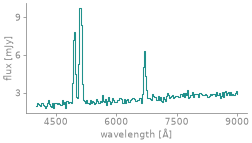
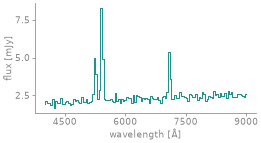
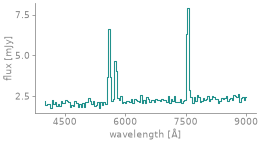
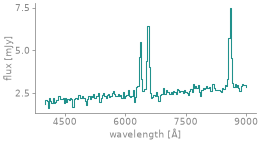

In [62]:
def make_spectra(redshifts, wave_unit="Å", flux_unit="mJy"):
    """A noisy spectrum with three emission lines for each redshift."""
    spectra = []
    for z in redshifts:
        wave = np.linspace(4000, 9000, rng.integers(120, 200))
        flux = 2 + rng.uniform(0, 1) * (wave - 4000) / 5000  # continuum
        for rest_wave in (4861.0, 5007.0, 6563.0):  # Hβ, [O III], Hα
            flux = flux + rng.uniform(2, 8) * np.exp(-0.5 * ((wave - rest_wave * (1 + z)) / 25) ** 2)
        flux = flux + rng.normal(0, 0.15, len(wave))
        spectra.append(Spectrum(wave.round(1), flux.round(3), wave_unit, flux_unit))
    return SpectrumArray._from_sequence(spectra)


galaxies = NestedFrame(
    {"ra": [10.1, 10.4, 11.2, 11.9], "z": [0.02, 0.08, 0.15, 0.31]},
    index=pd.Index(range(200, 204), name="object_id"),
)
galaxies["coadd"] = make_spectra(galaxies["z"])
galaxies

In [63]:
print(galaxies)

             ra     z                       coadd
object_id                                        
200        10.1  0.02  Spectrum(192 bins, Å, mJy)
201        10.4  0.08  Spectrum(126 bins, Å, mJy)
202        11.2  0.15  Spectrum(133 bins, Å, mJy)
203        11.9  0.31  Spectrum(165 bins, Å, mJy)


The column is a `SpectrumSeries`, so the spectrum methods are right there. Dividing the wavelength of the
brightest bin by `1 + z` lands on one of the three lines, 4861, 5007 or 6563 Å.

In [64]:
spectra = galaxies["coadd"]
print(type(spectra).__name__, "|", spectra.dtype)
pd.DataFrame(
    {
        "n_bins": spectra.n_bins(),
        "mean_flux": spectra.mean_flux().round(2),
        "peak_wave": spectra.peak_wave(),
        "peak_rest_wave": (spectra.peak_wave() / (1 + galaxies["z"])).round(0),
    }
)

SpectrumSeries | spectrum[Å, mJy]


,n_bins,mean_flux,peak_wave,peak_rest_wave
object_id,,,,
200,192,2.72,5099.5,5000.0
201,126,2.43,5400.0,5000.0
202,133,2.37,7560.6,6574.0
203,165,2.61,8603.7,6568.0


One value is a `Spectrum`:

In [65]:
one = spectra[200]
print(one)
one.to_frame().head(3)

Spectrum(192 bins, Å, mJy)


,wave,flux
0,4000.0,1.941
1,4026.2,1.929
2,4052.4,2.176


The units are part of the type. The dtype is registered with pandas, so its name, units included, is
a dtype anywhere pandas takes one, and spectra in other units are a different dtype.

spectrum[Å, mJy] | spectrum[nm, Jy] | same dtype: False


,spectrum
0,

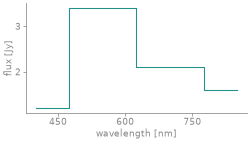

In [66]:
in_nm = pd.Series([Spectrum([400.0, 550.0, 700.0, 850.0], [1.2, 3.4, 2.1, 1.6], "nm", "Jy")], dtype="spectrum[nm, Jy]")
print(spectra.dtype, "|", in_nm.dtype, "| same dtype:", spectra.dtype == in_nm.dtype)
NestedFrame({"spectrum": in_nm})

### Inside a nested column: light curves of spectra, again

The same structure as Part 2, a light curve whose every epoch has a spectrum, but with the spectrum as
a single typed value, next to the co-added one. Each epoch's spectrum is plotted with its units inside the table of its light
curve, and the sub-column still comes back as a `SpectrumSeries`.

nested<mjd: [double], spectrum: [spectrum[Å, mJy]]>


z                                                 lc
object_id                                                         
200        0.02  [{mjd: 60017.9, spectrum: Spectrum(199 bins, Å...
201        0.08  [{mjd: 60090.9, spectrum: Spectrum(181 bins, Å...
202        0.15  [{mjd: 60068.2, spectrum: Spectrum(153 bins, Å...
203        0.31  [{mjd: 60082.7, spectrum: Spectrum(129 bins, Å...
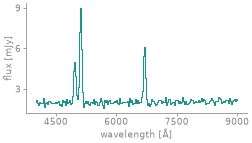
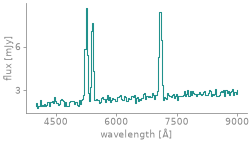
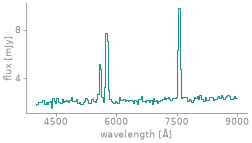
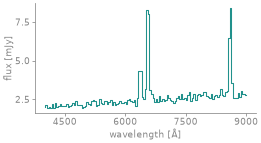

In [67]:
n_epochs = 3
object_of_epoch = np.repeat(galaxies.index, n_epochs)
epochs = pd.DataFrame(
    {
        "mjd": np.round(60000 + rng.uniform(0, 100, len(object_of_epoch)), 1),
        "spectrum": make_spectra(np.repeat(galaxies["z"].to_numpy(), n_epochs)),
    },
    index=object_of_epoch,
)
galaxies = galaxies.join_nested(epochs, "lc")
print(galaxies.dtypes["lc"])
galaxies[["z", "lc"]]

In [68]:
with pd.option_context("display.max_colwidth", 120, "display.width", 200):
    print(galaxies[["z", "lc"]])

              z                                                                  lc
object_id                                                                          
200        0.02  [{mjd: 60017.9, spectrum: Spectrum(199 bins, Å, mJy)}; …] (3 rows)
201        0.08  [{mjd: 60090.9, spectrum: Spectrum(181 bins, Å, mJy)}; …] (3 rows)
202        0.15  [{mjd: 60068.2, spectrum: Spectrum(153 bins, Å, mJy)}; …] (3 rows)
203        0.31  [{mjd: 60082.7, spectrum: Spectrum(129 bins, Å, mJy)}; …] (3 rows)


In [69]:
for how, series in {
    'galaxies["lc.spectrum"]': galaxies["lc.spectrum"],
    'galaxies["lc"].nest["spectrum"]': galaxies["lc"].nest["spectrum"],
    'galaxies["lc"][200]["spectrum"]': galaxies["lc"][200]["spectrum"],
    'galaxies.explode("lc")["spectrum"]': galaxies.explode("lc")["spectrum"],
}.items():
    print(f"{how:36s} {type(series).__name__:15s} {len(series):2d} values")

galaxies["lc.spectrum"].n_bins().tolist()

galaxies["lc.spectrum"]              SpectrumSeries  12 values
galaxies["lc"].nest["spectrum"]      SpectrumSeries  12 values
galaxies["lc"][200]["spectrum"]      SpectrumSeries   3 values
galaxies.explode("lc")["spectrum"]   SpectrumSeries  12 values


[199, 153, 139, 181, 136, 188, 153, 183, 120, 129, 176, 167]

The name of the nested dtype round-trips, units and all, since pandas knows `spectrum[...]`:

In [70]:
name = str(galaxies.dtypes["lc"])
pd.api.types.pandas_dtype(name) == galaxies.dtypes["lc"]

True

Measurements from the spectrum methods go back in as ordinary sub-columns, and filtering, missing rows
and parquet all carry the spectra along:

epochs: 12 -> 6
after reindex: [False, True]


SpectrumSeries | spectrum[Å, mJy] | read back from parquet


z                                                 lc
object_id                                                         
200        0.02  [{mjd: 60078.7, spectrum: Spectrum(139 bins, Å...
201        0.08  [{mjd: 60029.9, spectrum: Spectrum(188 bins, Å...
202        0.15  [{mjd: 60068.2, spectrum: Spectrum(153 bins, Å...
203        0.31  [{mjd: 60082.7, spectrum: Spectrum(129 bins, Å...
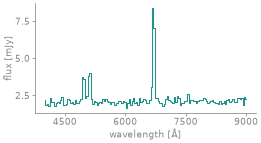
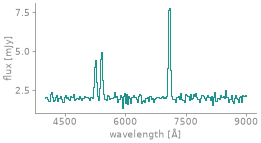
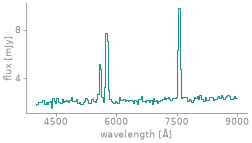
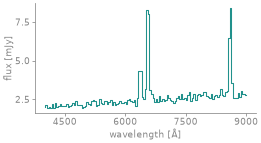

In [71]:
galaxies["lc.peak_wave"] = galaxies["lc.spectrum"].peak_wave().to_numpy()
red_peak = galaxies.query("lc.peak_wave > 6000")
print("epochs:", len(galaxies["lc.mjd"]), "->", len(red_peak["lc.mjd"]))
print("after reindex:", galaxies.reindex([200, 999])["lc"].isna().tolist())

with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "galaxies.parquet"
    galaxies.to_parquet(path)
    loaded = npd.read_parquet(path)
print(type(loaded["lc.spectrum"]).__name__, "|", loaded["lc.spectrum"].dtype, "| read back from parquet")
red_peak[["z", "lc"]]

### Back to a nested column, and all the way down

`to_nested()` re-reads the spectra as an ordinary nested column, which gives exactly the layout of
Part 2: every wavelength bin is addressable by a path again, two levels down.

In [72]:
galaxies["lc.spec"] = galaxies["lc.spectrum"].to_nested()
galaxies = galaxies.drop(columns=["coadd", "lc.spectrum"])
print(galaxies.dtypes["lc"])
red = galaxies.query("lc.spec.wave > 6500")
print("wavelength bins:", len(galaxies["lc.spec.wave"]), "->", len(red["lc.spec.wave"]))
red.compact_view()

nested<mjd: [double], peak_wave: [double], spec: [nested<wave: [double], flux: [double]>]>


wavelength bins: 1924 -> 958


ra     z                                                 lc
object_id                                                               
200        10.1  0.02  [{mjd: 60017.9, peak_wave: 5111.1, spec: [wave...
201        10.4  0.08  [{mjd: 60090.9, peak_wave: 5250.0, spec: [wave...
202        11.2  0.15  [{mjd: 60068.2, peak_wave: 7552.6, spec: [wave...
203        11.9  0.31  [{mjd: 60082.7, peak_wave: 8609.4, spec: [wave...